In [2]:
import numpy as np
import joblib
import tensorflow as tf
from sklearn.preprocessing import StandardScaler

# ──────────────────────────────────────────────
# 1. LOAD DATA
# ──────────────────────────────────────────────
land_ocean_tag = "ocean"

data_base_path_jan = "/work/bb1097/b383521/GW_Data/Data_set_ML/"
data_base_path_aug = "/work/bb1097/b383521/GW_Data_Summer/Data_set_ML/"

Data_Base_jan = joblib.load(data_base_path_jan + "corsed_action_" + land_ocean_tag + ".pkl")
Data_Base_aug = joblib.load(data_base_path_aug + "corsed_action_" + land_ocean_tag + ".pkl")

X_train = np.concatenate(
    [Data_Base_jan["X_train"], Data_Base_aug["X_train"]],
    axis=1,
)

X_test = np.concatenate(
    [Data_Base_jan["X_test"], Data_Base_aug["X_test"]],
    axis=1,
)

y_test = np.concatenate(
    [Data_Base_jan["y_test"], Data_Base_aug["y_test"]],
    axis=1,
)
y_test = np.nan_to_num(y_test, nan=0.0)

ntri_land = Data_Base_jan["ntri"]
n_features = X_train.shape[-1]
n_targets = y_test.shape[2] * y_test.shape[3] * y_test.shape[4]  # 6*6*4 = 144


# ──────────────────────────────────────────────
# 3. RESHAPE
# ──────────────────────────────────────────────
X_train       = X_train.reshape(-1, n_features)
X_test        = X_test.reshape(-1, n_features)
y_test        = y_test.reshape(-1, n_targets)

# ──────────────────────────────────────────────
# 4. SCALE (fit scaler on training data only, apply to both test versions)
# ──────────────────────────────────────────────
x_scaler = StandardScaler()
X_train       = x_scaler.fit_transform(X_train)
X_test    = x_scaler.transform(X_test)
del X_train
# ──────────────────────────────────────────────
# 5. LOAD MODEL AND PREDICT
# ──────────────────────────────────────────────
save_dir   = "/work/bb1097/b383521/ML_models/coarsed_grained/"
ML_dir     = save_dir + "models/"
fname_model = f"cnn_coarsed_{land_ocean_tag}.keras"

model = tf.keras.models.load_model(
    ML_dir + fname_model,
    custom_objects=False, compile=False
)

y_test_oro_pred    = model.predict(X_test)

E0000 00:00:1787318140.568652  273378 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


16305/16305 ━━━━━━━━━━━━━━━━━━━━ 45s 3ms/step


In [3]:
from Flux_energy import compute_intrinsic_feq_cgz
cgz, intrinsic_freq, k_lunch, l_lunch, m_lunch = compute_intrinsic_feq_cgz()

In [ ]:
y_test_pred = np.expm1(y_test_oro_pred).reshape(len(ntri_land), 44, 144)
y_test_true = y_test.reshape(len(ntri_land), 44, 144)
F_pred = y_test_pred*cgz[ntri_land, ...]
F_true = y_test_true*cgz[ntri_land, ...]
E_pred = y_test_pred*intrinsic_freq[ntri_land, ...]
E_true = y_test_true*intrinsic_freq[ntri_land, ...]
MSE_F = np.mean(np.abs(F_pred - F_true), axis=(0, 1))/np.std(F_true, axis=(0, 1))
MSE_E = np.mean(np.abs(E_pred - E_true), axis=(0, 1))/np.std(E_true, axis=(0, 1))

In [32]:
MSE_F = np.mean(np.abs(F_pred - F_true), axis=(0, 1))/np.std(F_true, axis=(0, 1))
MSE_E = np.mean(np.abs(E_pred - E_true), axis=(0, 1))/np.std(E_true, axis=(0, 1))

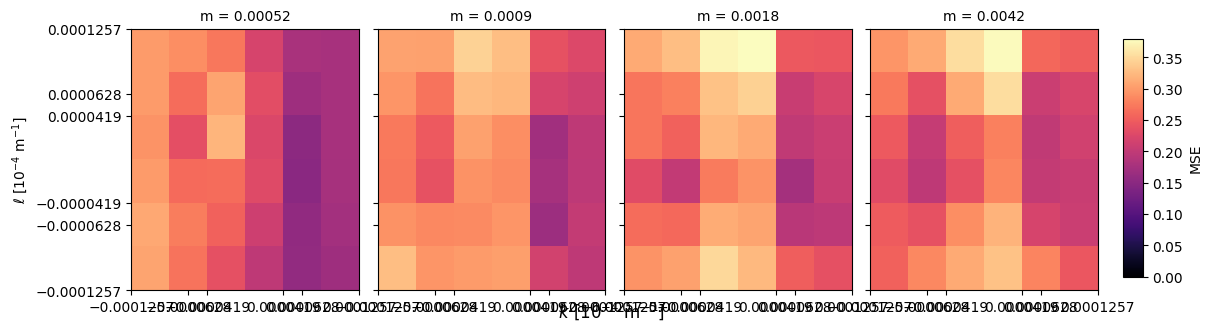

In [33]:
import matplotlib.pyplot as plt
def plot_spectral_mse(MSE, k_lunch, l_lunch, m_lunch, cmap="magma",
                       label="MSE", suptitle=None):
    """
    MSE: array of shape (n_k, n_l, n_m)
    Plots one heatmap panel per m_lunch value, sharing a single colorbar.
    """
    n_k, n_l, n_m = MSE.shape
    vmin, vmax = 0.0, np.nanmax(MSE)

    fig, axes = plt.subplots(
        1, n_m, figsize=(3.2 * n_m, 3.4), sharex=True, sharey=True
    )
    if n_m == 1:
        axes = [axes]

    for i, ax in enumerate(axes):
        im = ax.imshow(
            MSE[:, :, i].T,          # transpose so rows=l (y), cols=k (x)
            origin="lower",
            aspect="auto",
            cmap=cmap,
            vmin=vmin, vmax=vmax,
            extent=[k_lunch.min(), k_lunch.max(),
                    l_lunch.min(), l_lunch.max()],
        )
        ax.set_title(f"m = {m_lunch[i]:.2g}", fontsize=10)
        ax.set_xticks(k_lunch)
        ax.set_yticks(l_lunch)
        if i == 0:
            ax.set_ylabel(r"$\ell\ [10^{-4}\ \mathrm{m}^{-1}]$")

    fig.supxlabel(r"$k\ [10^{-4}\ \mathrm{m}^{-1}]$", y=0.02)

    # shared colorbar on the right
    fig.subplots_adjust(right=0.88, wspace=0.08)
    cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.7])
    cbar = fig.colorbar(im, cax=cbar_ax)
    cbar.set_label(label)

    if suptitle:
        fig.suptitle(suptitle, y=1.02)

    return fig, axes

fig, axes = plot_spectral_mse(MSE_F.reshape(6, 6, 4), k_lunch, l_lunch, m_lunch, label="MSE")
plt.show()

In [29]:
np.max(y_test_pred)

2164127.2

In [30]:
np.max(y_test)

9671849.0

In [31]:
np.max(y_test_pred)/np.max(y_test)

0.2237552767831673